# Notebook 05: Grammar-Specific Features & Fluency Indicators

## Step 5 Overview & Requirements
This notebook extracts grammar-specific indicators, speech rate alignment metrics, disfluency markers, syntactic structure indicators, and rule-based agreement heuristics.

### Scope & Design Constraints:
1. **Tool Audit & Feasibility**: External NLP tools like `language_tool_python` (requires Java runtime) and `spacy` (requires `en_core_web_sm` model binary) were inspected. Since Java and `en_core_web_sm` are absent in the local execution environment, we implement defensible, rule-based heuristics and alignment metrics without introducing unverified dependencies or artificial error counts.
2. **Speech Rate & Fluency Alignment**: Combines audio features (`duration_sec`, `speech_duration_ratio`, `pause_count`, `silence_duration_ratio`) with transcript text word counts to measure `speech_rate_wpm`, `articulation_rate_wps`, `pause_per_word_ratio`, and `silence_sec_per_word`.
3. **Disfluency & Fillers**: Extracts exact counts and ratios for filler words (`um`, `uh`, `like`, `you know`, etc.), adjacent word repetitions, and phrase repetitions.
4. **Syntactic Complexity & Grammar Heuristics**: Extracts subject-verb agreement mismatch patterns, double negatives, article misuse heuristics (`a`/`an`), sentence fragment ratios, run-on sentence ratios, conjunction usage, and passive voice patterns.
5. **Data Preservation**: Preserves exact filename ordering across 769 training and 216 test samples. Explicitly handles `audio_5055.wav` with status `FAILED_TRANSCRIPTION_DEFAULT_FEATURES`.

In [1]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Add src directory to path
if os.path.exists('src'):
    sys.path.insert(0, os.path.abspath('src'))
elif os.path.exists('../src'):
    sys.path.insert(0, os.path.abspath('../src'))

from grammar_features import compute_grammar_and_fluency_features, extract_text_grammar_indicators

def resolve_path(path_str):
    if os.path.exists(path_str):
        return path_str
    alt_path = os.path.join('..', path_str)
    if os.path.exists(alt_path):
        return alt_path
    return path_str

# Set plot styling
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
print('Setup and imports completed successfully.')

Setup and imports completed successfully.


## 1. Load Transcripts and Audio Features
Load training and test transcripts along with audio features for multimodal alignment.

In [2]:
train_trans_path = resolve_path('artifacts/transcripts/train_transcripts.csv')
test_trans_path = resolve_path('artifacts/transcripts/test_transcripts.csv')
train_audio_path = resolve_path('artifacts/features/train_audio_features.csv')
test_audio_path = resolve_path('artifacts/features/test_audio_features.csv')

train_trans = pd.read_csv(train_trans_path)
test_trans = pd.read_csv(test_trans_path)
train_audio = pd.read_csv(train_audio_path)
test_audio = pd.read_csv(test_audio_path)

print(f'Train Transcripts: {train_trans.shape}')
print(f'Test Transcripts:  {test_trans.shape}')
print(f'Train Audio Features: {train_audio.shape}')
print(f'Test Audio Features:  {test_audio.shape}')

Train Transcripts: (769, 6)
Test Transcripts:  (216, 6)
Train Audio Features: (769, 155)
Test Audio Features:  (216, 155)


## 2. Compute Grammar and Fluency Alignment Features
Extract features using `compute_grammar_and_fluency_features`.

In [3]:
train_grammar = compute_grammar_and_fluency_features(train_trans, train_audio)
test_grammar = compute_grammar_and_fluency_features(test_trans, test_audio)

print(f'Extracted Train Grammar Features shape: {train_grammar.shape}')
print(f'Extracted Test Grammar Features shape:  {test_grammar.shape}')
print('\nFeature list (first 15):')
print(list(train_grammar.columns[:15]))

Extracted Train Grammar Features shape: (769, 27)
Extracted Test Grammar Features shape:  (216, 27)

Feature list (first 15):
['filename', 'speech_rate_wpm', 'articulation_rate_wps', 'pause_per_word_ratio', 'silence_sec_per_word', 'words_per_pause', 'mean_pause_duration_sec', 'filler_word_count', 'filler_word_ratio', 'word_repetition_count', 'word_repetition_ratio', 'phrase_repetition_count', 'sv_agreement_error_count', 'sv_agreement_error_ratio', 'double_negative_count']


## 3. Data Integrity & Alignment Verification
Verify row counts (769 train, 216 test), filename alignment, absence of NaNs/Infs, and explicit status of failed transcript (`audio_5055.wav`).

In [4]:
# Check row counts
assert len(train_grammar) == 769, f'Expected 769 train rows, got {len(train_grammar)}'
assert len(test_grammar) == 216, f'Expected 216 test rows, got {len(test_grammar)}'

# Check filename alignment
assert list(train_grammar['filename']) == list(train_trans['filename']), 'Train filename mismatch!'
assert list(test_grammar['filename']) == list(test_trans['filename']), 'Test filename mismatch!'

# Check NaN and Inf counts
train_nans = train_grammar.isna().sum().sum()
test_nans = test_grammar.isna().sum().sum()
assert train_nans == 0, f'Train NaN count: {train_nans}'
assert test_nans == 0, f'Test NaN count: {test_nans}'

# Check audio_5055.wav explicitly
row_5055 = train_grammar[train_grammar['filename'] == 'audio_5055.wav']
print('--- Verification Report ---')
print(f'Train Rows: {len(train_grammar)} (Expected: 769)')
print(f'Test Rows:  {len(test_grammar)} (Expected: 216)')
print(f'Train NaNs: {train_nans}')
print(f'Test NaNs:  {test_nans}')
print('\nExplicit Status for audio_5055.wav:')
print(row_5055[['filename', 'grammar_feature_status', 'speech_rate_wpm', 'filler_word_count', 'sv_agreement_error_count']])

--- Verification Report ---
Train Rows: 769 (Expected: 769)
Test Rows:  216 (Expected: 216)
Train NaNs: 0
Test NaNs:  0

Explicit Status for audio_5055.wav:
          filename  ... sv_agreement_error_count
17  audio_5055.wav  ...                        0

[1 rows x 5 columns]


## 4. Visualizations & Feature Explorations
Explore distributions of speech rate, articulation rate, disfluency markers, and correlations.

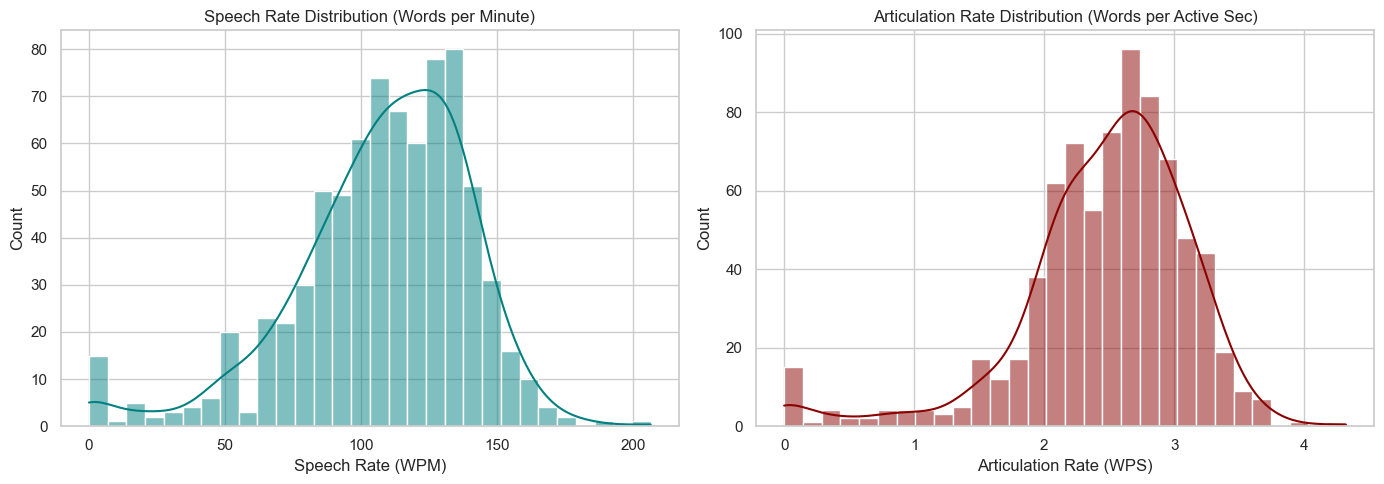

In [5]:
# Plot 1: Speech Rate and Articulation Rate Distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(train_grammar['speech_rate_wpm'], ax=axes[0], color='teal', kde=True, bins=30)
axes[0].set_title('Speech Rate Distribution (Words per Minute)')
axes[0].set_xlabel('Speech Rate (WPM)')

sns.histplot(train_grammar['articulation_rate_wps'], ax=axes[1], color='darkred', kde=True, bins=30)
axes[1].set_title('Articulation Rate Distribution (Words per Active Sec)')
axes[1].set_xlabel('Articulation Rate (WPS)')

plt.tight_layout()
plt.show()

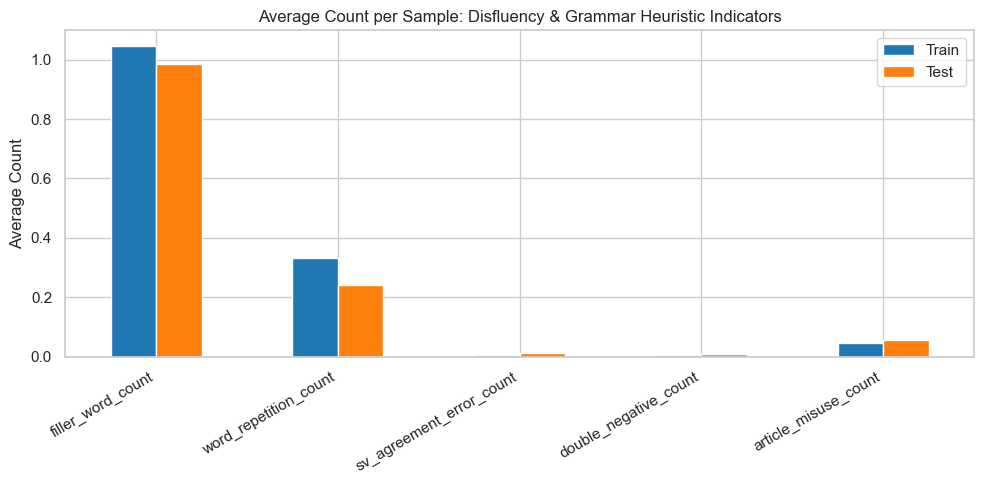

In [6]:
# Plot 2: Disfluency & Grammar Error Heuristic Counts
error_cols = ['filler_word_count', 'word_repetition_count', 'sv_agreement_error_count', 'double_negative_count', 'article_misuse_count']
mean_counts_train = train_grammar[error_cols].mean()
mean_counts_test = test_grammar[error_cols].mean()

df_counts = pd.DataFrame({'Train': mean_counts_train, 'Test': mean_counts_test})
ax = df_counts.plot(kind='bar', figsize=(10, 5), color=['#1f77b4', '#ff7f0e'])
plt.title('Average Count per Sample: Disfluency & Grammar Heuristic Indicators')
plt.ylabel('Average Count')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

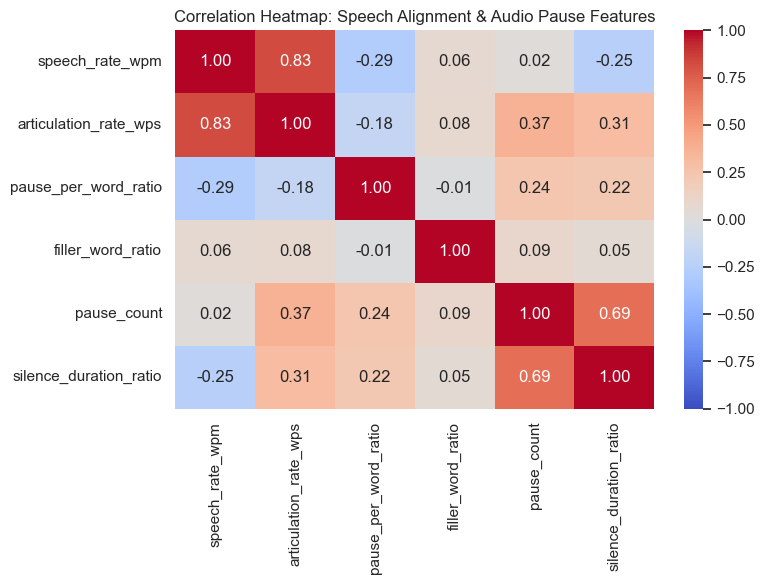

In [7]:
# Plot 3: Correlation Matrix between Fluency Indicators & Audio Pause Metrics
aligned_train = pd.merge(train_grammar, train_audio[['filename', 'pause_count', 'silence_duration_ratio', 'mean_pause_duration_sec']], on='filename')
corr_cols = ['speech_rate_wpm', 'articulation_rate_wps', 'pause_per_word_ratio', 'filler_word_ratio', 'pause_count', 'silence_duration_ratio']
corr_matrix = aligned_train[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap: Speech Alignment & Audio Pause Features')
plt.tight_layout()
plt.show()

## 5. Export Features & Summary
Save `train_grammar_features.csv` and `test_grammar_features.csv` to `artifacts/features/`.

In [8]:
out_train_path = resolve_path('artifacts/features/train_grammar_features.csv')
out_test_path = resolve_path('artifacts/features/test_grammar_features.csv')

train_grammar.to_csv(out_train_path, index=False)
test_grammar.to_csv(out_test_path, index=False)

print(f'Successfully saved Train Grammar Features to: {out_train_path} ({train_grammar.shape})')
print(f'Successfully saved Test Grammar Features to:  {out_test_path} ({test_grammar.shape})')

Successfully saved Train Grammar Features to: artifacts/features/train_grammar_features.csv ((769, 27))
Successfully saved Test Grammar Features to:  artifacts/features/test_grammar_features.csv ((216, 27))
